# Probability and Statistics — Lab Assignment 4: Hypothesis Testing

### General rules
* Submit **both** this `.ipynb` file and its **HTML export**. Links to GitHub repositories are **not accepted**.
* **File names:** name both files `lab4_team<n>`, where `<n>` is your team id (given to you by the instructor). For example, `lab4_team10.ipynb` and `lab4_team10.html`.
* At the beginning of the notebook, fill in the **work breakdown structure**.
* For **each task** your final notebook must contain:
    * the code,
    * the statistics obtained (sample means, test statistics, or anything else you use to complete the task),
    * your conclusions (e.g. whether to reject the hypothesis) and explanations.
* Problem 4 uses the file `data.csv` (provided together with this notebook).
* Not following these instructions may result in point deduction, regardless of whether your implementation is correct.

### How this template works
* All **plotting and boilerplate code is already implemented** -- you do not need to touch it.
* Cells marked with `# TODO` are where you do the statistics: compute test statistics, rejection regions, p-values, and make decisions.
* Markdown cells marked with ✍️ are where you write explanations and conclusions.
* Plots automatically pick up the values you compute; until a value is filled in, the corresponding part of the plot is simply skipped.

## Team & work breakdown structure

✍️ *Fill in the table: who did what.*

| Student | Responsibilities | Est. hours |
|---|---|---|
| **Liubomyr Voskalo** | Team id and descriptive statistics; warm-up question (inverse transform); Kolmogorov–Smirnov theory and implementation of `ks_statistic` and `ks_2sample_statistic`; Problem 3(a) ($x$ vs $\mathcal N(0,1)$) and 3(b) ($\lvert x\rvert$ vs $\text{Exp}(1)$) with comments | 7 |
| **Sophia** | Problem 2 (F-test for variances); Problem 4(a)–(b) (scatter plot, least-squares fit computed by hand and checked against `linregress`); Problem 4(c)–(d) ($R^2$, residual analysis, slope t-test) | 7 |
| **Yuna** | Problem 1 (two-sample Z-test); Problem 3(c) (two-sample KS test); Problem 4(e)–(f) (prediction for 8 hours, prediction interval, improvement ideas); final summary, consistency check of all conclusions, and HTML export | 7 |

The **team id** $n$ is given to you by the instructor. The answers depend on it, so make sure it is correct.

In [22]:
# Team id given by the instructor
TEAM_ID = 19

assert TEAM_ID is not None, "Fill in TEAM_ID first"
TEAM_ID = int(TEAM_ID)
print("Team id n =", TEAM_ID)

Team id n = 19


## Setup and plotting helpers
*Already implemented — just run the cell.*

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
C_MAIN, C_ALT, C_REJ, C_OBS = "#2a6fdb", "#e07b39", "#d64545", "#1b1b1b"


def _ready(*vals):
    """True if every value has been filled in by the student."""
    return all(v is not None and v is not Ellipsis for v in vals)


def _fmt(v, nd=4):
    if not _ready(v):
        return "— (not computed yet)"
    if isinstance(v, (bool, np.bool_)):
        return str(bool(v))
    if isinstance(v, (int, np.integer)) or (isinstance(v, (float, np.floating)) and float(v).is_integer() and abs(v) < 1e6):
        return str(int(v))
    if isinstance(v, (float, np.floating)):
        return f"{v:.{nd}g}" if abs(v) < 1e-3 and v != 0 else f"{v:.{nd}f}"
    return str(v)


def report(title, **values):
    """Pretty-print a block of named results."""
    print(f"── {title} " + "─" * max(0, 50 - len(title)))
    width = max(len(k) for k in values)
    for k, v in values.items():
        print(f"  {k:<{width}} : {_fmt(v)}")


def compare(name, mine, reference, tol=1e-6):
    """Compare a hand-computed value with a library value."""
    if not (_ready(mine) and _ready(reference)):
        print(f"  {name}: fill in both values to compare")
        return
    ok = np.isclose(mine, reference, rtol=tol, atol=tol)
    print(f"  {'ok' if ok else 'not ok'} {name}: yours = {mine:.6g}, library = {reference:.6g}")


def plot_samples(x, y):
    """Histograms with the N(0,1) density and normal Q-Q plots for both samples."""
    fig, ax = plt.subplots(2, 2, figsize=(10, 7))
    grid = np.linspace(-3.5, 3.5, 400)
    for col, (s, name, c) in enumerate([(x, "x", C_MAIN), (y, "y", C_ALT)]):
        a = ax[0, col]
        a.hist(s, bins="auto", density=True, color=c, alpha=0.55, edgecolor="white")
        a.plot(grid, stats.norm.pdf(grid), color=C_OBS, lw=1.5, label="N(0,1) pdf")
        a.set_title(f"Histogram of {name}  (size {len(s)})")
        a.legend()
        stats.probplot(s, dist="norm", plot=ax[1, col])
        ax[1, col].get_lines()[0].set(color=c, markersize=4)
        ax[1, col].get_lines()[1].set(color=C_OBS)
        ax[1, col].set_title(f"Normal Q-Q plot of {name}")
    fig.tight_layout()
    plt.show()


def plot_test_distribution(dist, observed=None, reject_left=None, reject_right=None,
                           title="Null distribution of the test statistic", xlabel="statistic"):
    """Density of the test statistic under H0, shaded rejection region, observed value.

    dist          : a frozen scipy distribution, e.g. stats.norm(), stats.f(dfn, dfd), stats.t(df)
    reject_left   : reject H0 when statistic <= reject_left   (None if not used)
    reject_right  : reject H0 when statistic >= reject_right  (None if not used)
    """
    lo, hi = dist.ppf(0.0005), dist.ppf(0.9995)
    if _ready(observed):
        span = hi - lo
        lo, hi = min(lo, observed - 0.1 * span), max(hi, observed + 0.1 * span)
    xs = np.linspace(lo, hi, 800)
    ys = dist.pdf(xs)
    fig, ax = plt.subplots()
    ax.plot(xs, ys, color=C_MAIN, lw=2, label="density under $H_0$")
    if _ready(reject_left):
        m = xs <= reject_left
        ax.fill_between(xs[m], ys[m], color=C_REJ, alpha=0.35, label="rejection region")
        ax.axvline(reject_left, color=C_REJ, ls="--", lw=1)
    if _ready(reject_right):
        m = xs >= reject_right
        ax.fill_between(xs[m], ys[m], color=C_REJ, alpha=0.35,
                        label=None if _ready(reject_left) else "rejection region")
        ax.axvline(reject_right, color=C_REJ, ls="--", lw=1)
    if _ready(observed):
        ax.axvline(observed, color=C_OBS, lw=2, label=f"observed = {observed:.3f}")
    ax.set(title=title, xlabel=xlabel, ylabel="density")
    ax.set_ylim(bottom=0)
    ax.legend()
    plt.show()


def _ecdf(sample):
    s = np.sort(np.asarray(sample))
    return s, np.arange(1, len(s) + 1) / len(s)


def plot_ecdf_vs_cdf(sample, cdf=None, other_sample=None, D=None, x_at_D=None,
                     labels=("sample", "reference"), title="Empirical vs reference CDF"):
    """ECDF of `sample` against a theoretical `cdf` (callable) or another sample's ECDF.
    If you pass your statistic D and the point x_at_D where it is attained,
    the maximal vertical distance is drawn on the plot."""
    s, F = _ecdf(sample)
    fig, ax = plt.subplots()
    ax.step(np.r_[s[0] - 0.5, s], np.r_[0, F], where="post", color=C_MAIN, lw=1.8,
            label=f"ECDF of {labels[0]}")
    lo, hi = s[0], s[-1]
    if other_sample is not None:
        s2, F2 = _ecdf(other_sample)
        lo, hi = min(lo, s2[0]), max(hi, s2[-1])
        ax.step(np.r_[s2[0] - 0.5, s2], np.r_[0, F2], where="post", color=C_ALT, lw=1.8,
                label=f"ECDF of {labels[1]}")
    if cdf is not None:
        xs = np.linspace(lo - 0.5, hi + 0.5, 600)
        ax.plot(xs, cdf(xs), color=C_ALT, lw=2, label=f"CDF of {labels[1]}")
    if _ready(D, x_at_D):
        def ecdf_limits(sorted_s, x):
            n = len(sorted_s)
            return (np.searchsorted(sorted_s, x, side="left") / n,
                    np.searchsorted(sorted_s, x, side="right") / n)
        a_l, a_r = ecdf_limits(s, x_at_D)
        if other_sample is not None:
            b_l, b_r = ecdf_limits(np.sort(other_sample), x_at_D)
            pairs = [(a_l, b_l), (a_r, b_r), (a_l, b_r), (a_r, b_l)]
        else:
            ref = float(cdf(np.array([x_at_D]))[0])
            pairs = [(a_l, ref), (a_r, ref)]
        p, q = min(pairs, key=lambda pq: abs(abs(pq[0] - pq[1]) - D))
        ax.vlines(x_at_D, min(p, q), max(p, q), color=C_REJ, lw=3, label=f"D = {D:.4f}")
    ax.set(title=title, xlabel="x", ylabel="F(x)")
    ax.legend(loc="lower right")
    plt.show()


def plot_regression(x, y, beta0=None, beta1=None, x_new=None, y_new=None,
                    xlabel="x", ylabel="y"):
    """Scatter plot, optionally with the fitted line and a prediction point."""
    fig, ax = plt.subplots()
    ax.scatter(x, y, color=C_MAIN, alpha=0.7, edgecolor="white", s=40, label="data")
    if _ready(beta0, beta1):
        xs = np.linspace(np.min(x), np.max(x) if not _ready(x_new) else max(np.max(x), x_new), 200)
        ax.plot(xs, beta0 + beta1 * xs, color=C_REJ, lw=2,
                label=f"$\\hat y = {beta0:.3f} + {beta1:.3f}\\,x$")
    if _ready(x_new, y_new):
        ax.scatter([x_new], [y_new], color=C_OBS, marker="*", s=220, zorder=5,
                   label=f"prediction at x={x_new}: {y_new:.2f}")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=f"{ylabel} vs {xlabel}")
    ax.legend()
    plt.show()


def plot_residuals(fitted, residuals):
    """Residuals vs fitted values, histogram and Q-Q plot of the residuals."""
    if not _ready(fitted, residuals):
        print("Compute `fitted` and `residuals` first.")
        return
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].scatter(fitted, residuals, color=C_MAIN, alpha=0.7, edgecolor="white")
    ax[0].axhline(0, color=C_OBS, lw=1)
    ax[0].set(title="Residuals vs fitted", xlabel="fitted", ylabel="residual")
    ax[1].hist(residuals, bins="auto", color=C_MAIN, alpha=0.6, edgecolor="white")
    ax[1].set(title="Histogram of residuals")
    stats.probplot(residuals, dist="norm", plot=ax[2])
    ax[2].get_lines()[0].set(color=C_MAIN, markersize=4)
    ax[2].set_title("Q-Q plot of residuals")
    fig.tight_layout()
    plt.show()

print("Helpers loaded.")

Helpers loaded.


## Data for Problems 1–3

Set
$$a_k := \{\,k \ln(k^2 n + \pi)\,\}, \qquad k \ge 1,$$
where $\{x\} = x - \lfloor x \rfloor$ is the fractional part and $n$ is the team id.
The samples $X_1,\dots,X_{100} \sim \mathcal N(\mu_1,\sigma_1^2)$ and $Y_1,\dots,Y_{50} \sim \mathcal N(\mu_2,\sigma_2^2)$ are
$$x_k = \Phi^{-1}(a_k),\quad k=1,\dots,100, \qquad y_l = \Phi^{-1}(a_{l+100}),\quad l = 1,\dots,50,$$
where $\Phi$ is the CDF of $\mathcal N(0,1)$.

In [24]:
def a(k, n=TEAM_ID):
    v = k * np.log(k**2 * n + np.pi)
    return v - np.floor(v)

a_data = a(np.arange(1, 151))
x = stats.norm.ppf(a_data[:100])
y = stats.norm.ppf(a_data[100:150])

print("first values of x:", x[:5])
print("first values of y:", y[:5])

first values of x: [-1.2962  0.651  -0.0511  1.3361  1.0344]
first values of y: [ 0.37    0.9496 -1.8385 -0.654  -0.0017]


✍️ **Warm-up question.** Why does applying $\Phi^{-1}$ to numbers that "look uniform on $(0,1)$" produce a sample that looks standard normal?
State the result (inverse transform method) and prove it in one or two lines: if $U\sim\mathcal U(0,1)$, what is $P(\Phi^{-1}(U)\le t)$?

*Your answer:*

**Inverse transform method.** If $U\sim\mathcal U(0,1)$ and $F$ is a continuous strictly increasing CDF, then the random variable $F^{-1}(U)$ has CDF $F$.

**Proof (for $F = \Phi$).** $\Phi$ is strictly increasing, so $\Phi^{-1}(U)\le t \iff U\le\Phi(t)$. Since $P(U\le u)=u$ for $u\in(0,1)$, we get for every $t\in\mathbb R$
$$P(\Phi^{-1}(U)\le t) = P(U\le\Phi(t)) = \Phi(t),$$
which is exactly the CDF of $\mathcal N(0,1)$. $\blacksquare$

The numbers $a_k$ are deterministic, but they are spread over $(0,1)$ like a sample from $\mathcal U(0,1)$. Therefore $\Phi^{-1}(a_k)$ should look like a sample from $\mathcal N(0,1)$.

Visual check of the generated samples *(implemented)*:

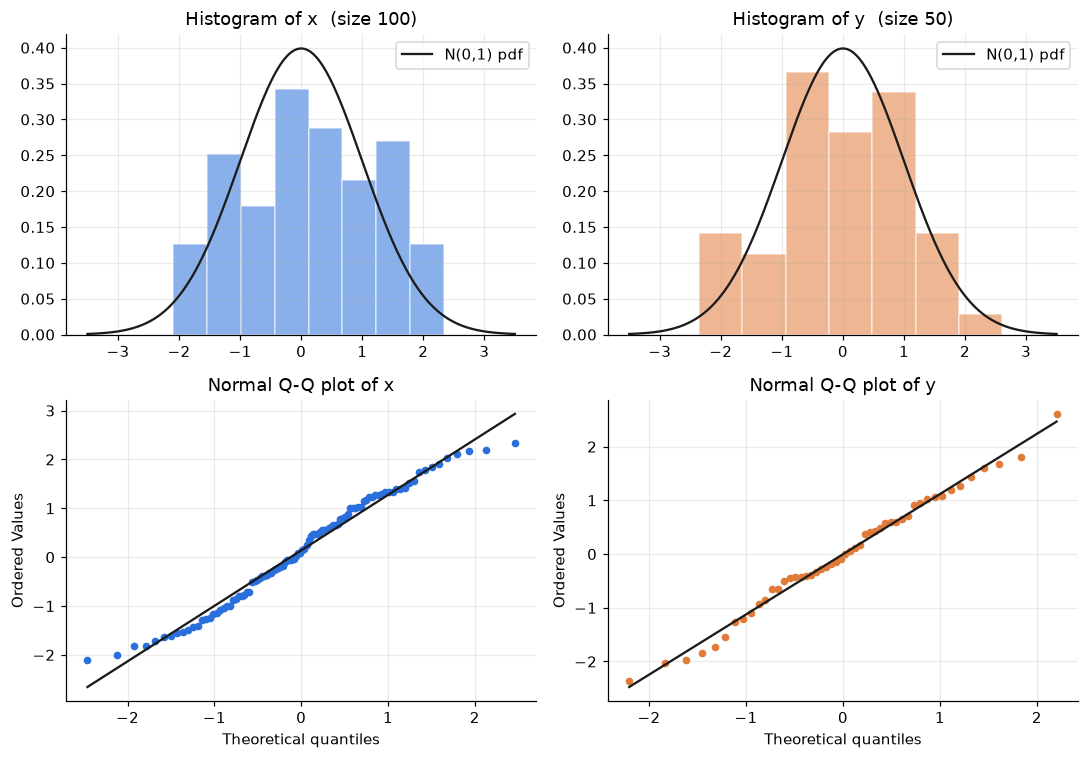

In [25]:
plot_samples(x, y)

### Descriptive statistics
Compute the basic sample statistics you will need below.
Remember: the **unbiased** sample variance divides by $n-1$ (`ddof=1` in NumPy).

In [26]:
n_x, n_y = len(x), len(y)
x_mean = np.mean(x)         # sample mean of x
y_mean = np.mean(y)         # sample mean of y
x_var  = np.var(x, ddof=1)  # unbiased sample variance of x
y_var  = np.var(y, ddof=1)  # unbiased sample variance of y

report("Descriptive statistics", n_x=n_x, n_y=n_y,
       x_mean=x_mean, y_mean=y_mean, x_var=x_var, y_var=y_var)

── Descriptive statistics ────────────────────────────
  n_x    : 100
  n_y    : 50
  x_mean : 0.1377
  y_mean : -0.0042
  x_var  : 1.2723
  y_var  : 1.2029


### Instructions for Problems 1–3
For each test $H_0$ vs $H_1$:
1. point out what standard test you use and **why**;
2. indicate the general form of the **rejection region** of the level-0.05 test;
3. find out whether $H_0$ should be **rejected** at significance level 0.05;
4. indicate the **p-value** and comment whether you would reject $H_0$ for that p-value and why.

---
## Problem 1
$$H_0:\ \mu_1 = \mu_2 \quad\text{vs.}\quad H_1:\ \mu_1 \ne \mu_2; \qquad \sigma_1^2=\sigma_2^2 = 1 \text{ (known)}.$$

✍️ **Choice of the test.** Which test do you use and why (what is known, what is the distribution of the statistic under $H_0$)?

*Your answer:* We use the two-sample Z-test for means. Both samples are normal and independent, and the variances are known ($\sigma_1^2=\sigma_2^2=1$). Then $\bar X - \bar Y$ is normal with known variance $\frac{\sigma_1^2}{n}+\frac{\sigma_2^2}{m}$, so after standardization we get exactly $\mathcal N(0,1)$ under $H_0$. Since the variances are known, we do not need the t-distribution.

✍️ **Test statistic.** Write the statistic and its distribution under $H_0$:
$$Z = \frac{\bar X - \bar Y}{\sqrt{\frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}}} \ \sim\ \mathcal N(0,1), \qquad n = 100,\ m = 50.$$

✍️ **Rejection region** of level $\alpha = 0.05$ (general form). The alternative is two-sided, so both large positive and large negative values of $Z$ contradict $H_0$:
$$C = \{\,|Z| \ge z_{1-\alpha/2}\,\} = \{\,|Z| \ge 1.96\,\}$$

In [27]:
sigma1_sq, sigma2_sq = 1.0, 1.0

z_stat    = (x_mean - y_mean) / np.sqrt(sigma1_sq / n_x + sigma2_sq / n_y)
z_crit    = stats.norm.ppf(1 - ALPHA / 2)
p_value_1 = 2 * (1 - stats.norm.cdf(abs(z_stat)))
reject_1  = abs(z_stat) >= z_crit

report("Problem 1: two-sample test for means", Z=z_stat, critical_value=z_crit,
       p_value=p_value_1, reject_H0=reject_1)

── Problem 1: two-sample test for means ──────────────
  Z              : 0.8189
  critical_value : 1.9600
  p_value        : 0.4128
  reject_H0      : False


Null distribution with your rejection region *(plot implemented)*:

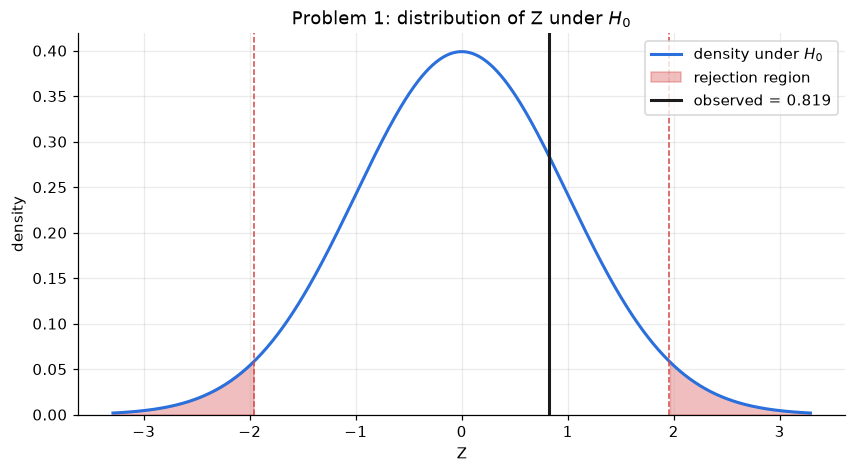

In [28]:
plot_test_distribution(
    stats.norm(),
    observed=z_stat,
    reject_left=None if z_crit is None else -z_crit,
    reject_right=z_crit,
    title="Problem 1: distribution of Z under $H_0$", xlabel="Z",
)

✍️ **Conclusion for Problem 1.** Do you reject $H_0$ at level 0.05? Interpret the p-value: what exactly is it the probability of?
Does the conclusion agree with what you know about how the data were generated?

*Your answer:*

The observed value is $Z = 0.819$. Since $|Z| = 0.819 < 1.96$, it is not in the rejection region, so we **do not reject** $H_0$ at level 0.05.

The p-value is $0.413$. It is the probability, assuming $H_0$ is true ($\mu_1 = \mu_2$), of getting a value of $|Z|$ at least as large as the observed one, i.e. a difference of sample means at least as large as ours in either direction. Since $0.413 > 0.05$, we do not reject $H_0$. We would reject it only at levels $\alpha \ge 0.413$, which nobody uses in practice.

This agrees with how the data were generated: both $x$ and $y$ are obtained from the same sequence $a_k$, so both should look like samples from $\mathcal N(0,1)$, and $\mu_1 = \mu_2 = 0$. The difference $\bar x - \bar y \approx 0.142$ is just random variation.

---
## Problem 2
$$H_0:\ \sigma_1^2 = \sigma_2^2 \quad\text{vs.}\quad H_1:\ \sigma_1^2 > \sigma_2^2; \qquad \mu_1, \mu_2 \text{ unknown}.$$

**Fact.** If $X_1,\dots,X_n \sim \mathcal N(\mu_1,\sigma_1^2)$ and $Y_1,\dots,Y_m \sim \mathcal N(\mu_2,\sigma_2^2)$ are independent samples and $S_1^2, S_2^2$ are their unbiased sample variances, then
$$\frac{S_1^2/\sigma_1^2}{S_2^2/\sigma_2^2} \sim F(n-1,\ m-1).$$

✍️ **Choice of the test.** Which test do you use and why (what is known, what is unknown)?

*Your answer:* ...

✍️ **Test statistic** under $H_0$:
$$F = \ldots \ \sim\ F(\ \cdot\ ,\ \cdot\ )$$

✍️ **Rejection region** of level 0.05 (note: the alternative is one-sided):
$$C = \{\ldots\}$$

In [29]:
# TODO
df1 = n_x - 1           # numerator degrees of freedom
df2 = n_y - 1           # denominator degrees of freedom
F_stat = x_var / y_var     # observed F statistic
F_crit = stats.f.ppf(0.95, df1, df2)     # reject H0 if F >= F_crit       (hint: stats.f.ppf)
p_value_2 = stats.f.sf(F_stat, df1, df2)     # one-sided p-value               (hint: stats.f.sf)
reject_2 = p_value_2 < ALPHA

report("Problem 2: F-test for variances", df1=df1, df2=df2, F=F_stat,
       critical_value=F_crit, p_value=p_value_2, reject_H0=reject_2)

── Problem 2: F-test for variances ───────────────────
  df1            : 99
  df2            : 49
  F              : 1.0578
  critical_value : 1.5310
  p_value        : 0.4215
  reject_H0      : False


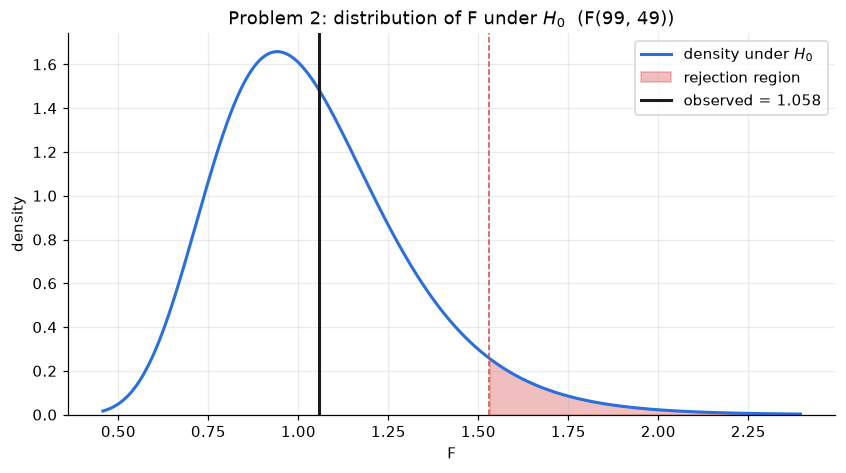

In [30]:
if _ready(df1, df2):
    plot_test_distribution(
        stats.f(df1, df2), observed=F_stat, reject_right=F_crit,
        title=f"Problem 2: distribution of F under $H_0$  (F({df1}, {df2}))", xlabel="F",
    )
else:
    print("Fill in df1 and df2 to see the plot.")

✍️ **Conclusion for Problem 2.** Reject or not at level 0.05? Comment on the p-value.
Why would it be wrong to use a two-sided rejection region here?

*Your answer:* 
At significance level \(\alpha=0.05\), we fail to reject the null hypothesis because the observed F-statistic \(F=1.0578\) is smaller than the critical value \(F_{crit}=1.5310\). The p-value \(0.4215\) is greater than \(0.05\), so there is insufficient evidence to conclude that the variance of the first population is greater than the variance of the second population.

Using a two-sided rejection region would be inappropriate because our alternative hypothesis specifically states that the first population variance is greater than the second. A two-sided test would also detect the opposite direction, which is not what we are testing.

---
## Problem 3 — Kolmogorov goodness-of-fit test and Kolmogorov–Smirnov test

Check whether
* **(a)** $\{x_k\}_{k=1}^{100}$ come from the standard normal distribution $\mathcal N(0,1)$, as the construction of the data suggests (see the warm-up question);
* **(b)** $\{|x_k|\}_{k=1}^{100}$ are exponentially distributed with $\lambda = 1$;
* **(c)** $\{x_k\}_{k=1}^{100}$ and $\{y_l\}_{l=1}^{50}$ have the same distribution.

In (a) and (b) a sample is compared with a given distribution $F_0$, so we use the **Kolmogorov goodness-of-fit test**. In (c) two samples are compared, so we use its two-sample modification, the **Kolmogorov–Smirnov test**. (In `scipy` the first is `stats.kstest` and the second is `stats.ks_2samp`.)

Explain the main idea behind these tests and comment on the outcome of each test (follow the instructions for Problems 1–3 above).

*Note:* here $\{x_k\}_{k=1}^{100}$ denotes the **set** of the hundred values $x_k$, **not** their fractional parts.

✍️ **Main idea of the tests.** Define the sample c.d.f. $\hat F_{\mathbf x}$ and the statistic
$d = \sup_{t} |\hat F_{\mathbf x}(t) - F_0(t)|$. Why should $d$ be small under $H_0$ and large under $H_1$? What is known about its distribution under $H_0$ (for continuous $F_0$)? What is the rejection region?
How is the test modified for two samples (Kolmogorov–Smirnov test)?

*Your answer:*

**Definitions.** For a sample $\mathbf x = (x_1,\dots,x_n)$ the sample (empirical) c.d.f. is the fraction of observations not exceeding $t$:
$$\hat F_{\mathbf x}(t) = \frac{1}{n}\,\#\{i : x_i\le t\}, \qquad d = \sup_{t\in\mathbb R}|\hat F_{\mathbf x}(t) - F_0(t)|.$$
We test $H_0: F = F_0$ vs. $H_1: F\ne F_0$, where $F$ is the true c.d.f. of the sample.

**Why $d$ measures the discrepancy.** By the Glivenko–Cantelli theorem, $\sup_t|\hat F_{\mathbf x}(t) - F(t)|\to 0$ almost surely as $n\to\infty$.
* Under $H_0$ we have $F = F_0$, so $d\to 0$ and small values of $d$ are expected.
* Under $H_1$ we have $d\to\sup_t|F(t)-F_0(t)| > 0$, so $d$ stays away from zero.

**Distribution under $H_0$.** If $F_0$ is continuous, then $F_0(X_i)\sim\mathcal U(0,1)$ under $H_0$. Hence $d$ has the same distribution for every continuous $F_0$: the Kolmogorov distribution $\mathscr D_n$, which depends only on $n$. For large $n$,
$$P(\sqrt n\,d\le t)\to K(t) = 1 - 2\sum_{k=1}^{\infty}(-1)^{k-1}e^{-2k^2t^2}, \qquad t>0.$$

**Rejection region** of level $\alpha = 0.05$: only large $d$ contradicts $H_0$, so the test is right-tailed:
$$C = \{\mathbf x : d\ge d^{(n)}_{1-\alpha}\},$$
where $d^{(n)}_{1-\alpha}$ is the quantile of level $1-\alpha$ of $\mathscr D_n$ (for large $n$, $d^{(n)}_{0.95}\approx 1.358/\sqrt n$). The p-value is $P(D\ge d)$ with $D\sim\mathscr D_n$, and we reject $H_0$ when p-value $\le\alpha$.

**Two samples (Kolmogorov–Smirnov test).** For independent samples of sizes $n$ and $m$ we test $H_0: F_X = F_Y$ vs. $H_1: F_X\ne F_Y$. There is no given $F_0$, so we compare the two sample c.d.f.s:
$$d = \sup_{t\in\mathbb R}|\hat F_{\mathbf x}(t) - \hat F_{\mathbf y}(t)|.$$
Under $H_0$ (with a continuous common c.d.f.) its distribution depends only on $n$ and $m$, and $\sqrt{\frac{nm}{n+m}}\,d$ has the same limit $K$. We reject $H_0$ when $d$ is at least the $(1-\alpha)$-quantile, which is $\approx 1.358\sqrt{\frac{n+m}{nm}}$ for $\alpha = 0.05$ and large samples.

### Your implementation of the test statistics
We need $d = \sup_{t\in\mathbb R} |\hat F_{\mathbf x}(t) - F_0(t)|$. A computer cannot check every real $t$, but it does not have to: $\hat F_{\mathbf x}$ is a step function that only jumps at the sample points, and $F_0$ is increasing between them. So the largest gap is always at one of the sorted sample points $x_{(1)} \le \dots \le x_{(n)}$, either **at** the jump (where $\hat F_{\mathbf x}(x_{(i)}) = \frac{i}{n}$) or **just before** it (where $\hat F_{\mathbf x} = \frac{i-1}{n}$). Therefore
$$d = \max_{i=1,\dots,n}\ \max\Big( \big|\tfrac{i}{n} - F_0(x_{(i)})\big|,\ \big|\tfrac{i-1}{n} - F_0(x_{(i)})\big| \Big).$$

In [31]:
def ks_statistic(sample, cdf):
    """Kolmogorov goodness-of-fit statistic d = sup_t |F_hat(t) - F0(t)|.

    sample : 1-D array
    cdf    : vectorised callable, the hypothesised CDF F0
    returns: (D, x_at_max) — the statistic and the sample point where the sup is attained
    """
    points = np.sort(sample)
    n = len(points)
    i = np.arange(1, n + 1)
    F0 = cdf(points)

    gap_at_jump = np.abs(i / n - F0)
    gap_before_jump = np.abs((i - 1) / n - F0)
    gaps = np.maximum(gap_at_jump, gap_before_jump)

    i_max = np.argmax(gaps)
    return gaps[i_max], points[i_max]


def ks_2sample_statistic(s1, s2):
    """Two-sample Kolmogorov–Smirnov statistic d = sup_t |F1_hat(t) - F2_hat(t)|.

    Hint: it is enough to evaluate both ECDFs at all points of the pooled sample
    (np.searchsorted(sorted_sample, points, side="right") / n gives an ECDF).
    returns: (D, x_at_max)
    """
    points = np.concatenate([s1, s2])
    F1 = np.searchsorted(np.sort(s1), points, side="right") / len(s1)
    F2 = np.searchsorted(np.sort(s2), points, side="right") / len(s2)
    gaps = np.abs(F1 - F2)

    i_max = np.argmax(gaps)
    return gaps[i_max], points[i_max]

### (a) Do $\{x_k\}_{k=1}^{100}$ come from $\mathcal N(0,1)$?

In [32]:
cdf_a = stats.norm.cdf                   # CDF of N(0, 1) as a vectorised callable

D_a, xD_a = ks_statistic(x, cdf_a) if cdf_a is not None else (None, None)

d_crit = stats.kstwo.ppf(1 - ALPHA, n_x)  # critical value: reject H0 if D >= d_crit

ks_a      = stats.kstest(x, cdf_a)       # library result
p_value_a = ks_a.pvalue
reject_a  = D_a >= d_crit

report("Problem 3(a): Kolmogorov test x ~ N(0, 1)", D_yours=D_a, critical_value=d_crit,
       p_value=p_value_a, reject_H0=reject_a)
if ks_a is not None:
    compare("D", D_a, ks_a.statistic)

── Problem 3(a): Kolmogorov test x ~ N(0, 1) ─────────
  D_yours        : 0.1317
  critical_value : 0.1340
  p_value        : 0.0566
  reject_H0      : False
  ok D: yours = 0.131722, library = 0.131722


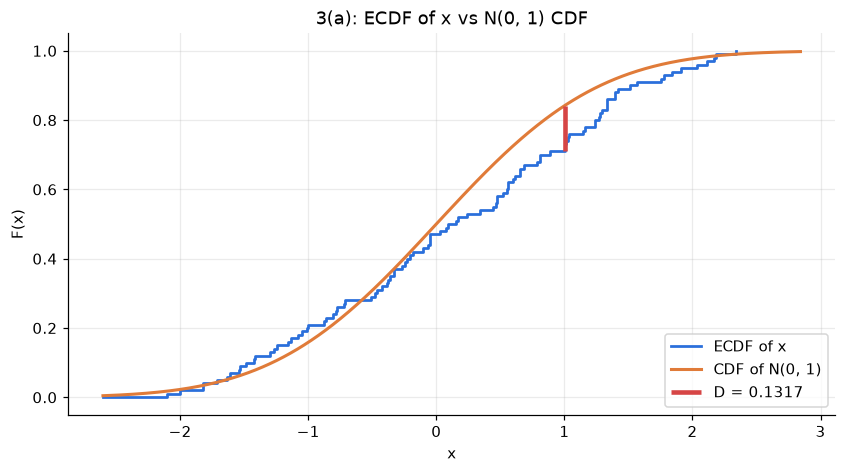

In [33]:
if cdf_a is not None:
    plot_ecdf_vs_cdf(x, cdf=cdf_a, D=D_a, x_at_D=xD_a, labels=("x", "N(0, 1)"),
                     title="3(a): ECDF of x vs N(0, 1) CDF")

✍️ **Comment on (a).** Reject or not? Interpret the p-value. If $H_0$ were rejected, could you tell whether the problem is the shape of the distribution or the values $\mu = 0$, $\sigma = 1$?

*Think further:* suppose that instead of $\mathcal N(0,1)$ we estimated $\mu$ and $\sigma$ from the same sample and compared $x$ with $\mathcal N(\bar x, s^2)$. Could we still use the Kolmogorov distribution $\mathscr D_n$ for the critical value? Would $d$ tend to be larger or smaller than for a fixed $F_0$, and what would that mean for the p-value?

*Your answer:*

1. **Test.** Kolmogorov goodness-of-fit test of $H_0: F = \Phi$ vs. $H_1: F\ne\Phi$. We compare one sample with a fully specified continuous distribution $\mathcal N(0,1)$, so $d\sim\mathscr D_{100}$ under $H_0$.
2. **Rejection region.** $C = \{\mathbf x : d\ge d^{(100)}_{0.95}\} = \{\mathbf x : d\ge 0.1340\}$.
3. **Decision.** The observed $d = 0.1317 < 0.1340$, so we **do not reject** $H_0$ at level 0.05. This agrees with the construction of the data, but the result is close to the boundary.
4. **p-value.** p-value $= 0.0566 > 0.05$, so we do not reject $H_0$ for this p-value either. It means that if $x$ really came from $\mathcal N(0,1)$, a distance of at least $0.1317$ would occur in about 5.7% of samples of size 100. We would reject $H_0$ only at levels $\alpha\ge 0.0566$, e.g. at $\alpha = 0.1$. Not rejecting does not prove that $H_0$ is true.

**If $H_0$ were rejected,** we could not tell the reason. $H_0$ fixes the shape, $\mu = 0$ and $\sigma = 1$ at once, and $d$ is a single number that reacts to any difference between $F$ and $\Phi$. To separate the reasons, we would need other tools, e.g. a Q-Q plot, tests for the mean and the variance, or a normality test with estimated parameters.

**Think further.** With $\mathcal N(\bar x, s^2)$ we could **not** use $\mathscr D_n$. Then $F_0$ is not fixed in advance but depends on the sample, so $F_0(X_i)$ are no longer independent $\mathcal U(0,1)$ variables. The fitted curve is adjusted to the same data, so $d$ tends to be **smaller** than for a fixed $F_0$. Compared with $\mathscr D_n$, the p-value would be **too large** and the test would reject too rarely: the true probability of a type I error would be much smaller than 0.05, and the test would lose power. The correct critical values for this case are given by the Lilliefors test.

### (b) Are $\{|x_k|\}_{k=1}^{100}$ exponentially distributed with $\lambda = 1$?

In [34]:
abs_x = np.abs(x)
cdf_b = stats.expon.cdf                  # CDF of Exp(1) as a vectorised callable

D_b, xD_b = ks_statistic(abs_x, cdf_b) if cdf_b is not None else (None, None)

ks_b      = stats.kstest(abs_x, cdf_b)   # library result
p_value_b = ks_b.pvalue
reject_b  = D_b >= d_crit                # same critical value as in (a): the sample size is also 100

report("Problem 3(b): Kolmogorov test |x| ~ Exp(1)", D_yours=D_b, critical_value=d_crit,
       p_value=p_value_b, reject_H0=reject_b)
if ks_b is not None:
    compare("D", D_b, ks_b.statistic)

── Problem 3(b): Kolmogorov test |x| ~ Exp(1) ────────
  D_yours        : 0.1327
  critical_value : 0.1340
  p_value        : 0.0538
  reject_H0      : False
  ok D: yours = 0.132695, library = 0.132695


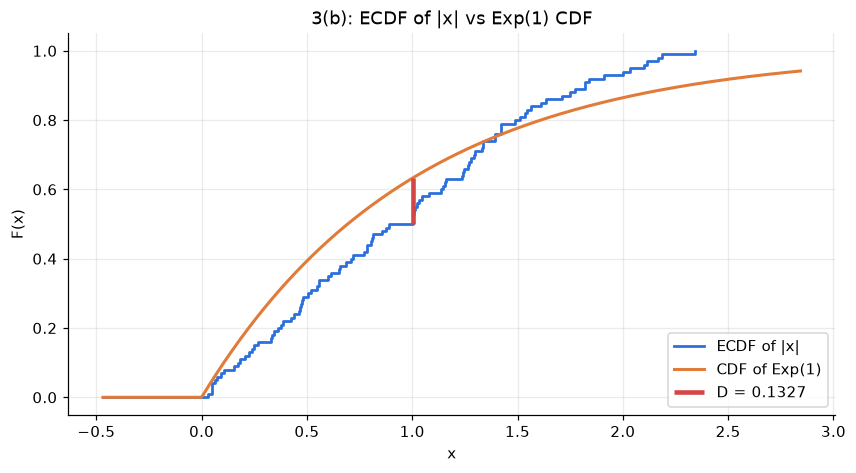

In [35]:
if cdf_b is not None:
    plot_ecdf_vs_cdf(abs_x, cdf=cdf_b, D=D_b, x_at_D=xD_b, labels=("|x|", "Exp(1)"),
                     title="3(b): ECDF of |x| vs Exp(1) CDF")

✍️ **Comment on (b).** Reject or not? If $X \sim \mathcal N(0,1)$, what is the actual distribution of $|X|$ (derive its CDF)?
Compare it with $\text{Exp}(1)$: where do the two CDFs differ the most, and does that match where your $D$ is attained?

*Your answer:*

1. **Test.** Kolmogorov goodness-of-fit test of $H_0: F = F_{\text{Exp}(1)}$ vs. $H_1: F\ne F_{\text{Exp}(1)}$, where $F$ is the true c.d.f. of $|x_k|$. The distribution $\text{Exp}(1)$ with $F_0(t) = 1 - e^{-t}$, $t\ge 0$, is continuous and fully specified, so $d\sim\mathscr D_{100}$ under $H_0$.
2. **Rejection region.** $C = \{d\ge d^{(100)}_{0.95}\} = \{d\ge 0.1340\}$.
3. **Decision.** The observed $d = 0.1327 < 0.1340$, so we **do not reject** $H_0$ at level 0.05, although the result is again close to the boundary.
4. **p-value.** p-value $= 0.0538 > 0.05$, so we do not reject $H_0$ for this p-value either. If $|x|$ really came from $\text{Exp}(1)$, a distance of at least $0.1327$ would occur in about 5.4% of samples of size 100.

**Actual distribution of $|X|$.** If $X\sim\mathcal N(0,1)$, then for $t\ge 0$
$$F_{|X|}(t) = P(-t\le X\le t) = \Phi(t) - \Phi(-t) = 2\Phi(t) - 1,$$
and $F_{|X|}(t) = 0$ for $t<0$. This is the half-normal distribution, not $\text{Exp}(1)$. So if $x$ comes from $\mathcal N(0,1)$, then $H_0$ is false and not rejecting it is a **type II error**.

**Where the two CDFs differ the most.** Let $g(t) = (2\Phi(t) - 1) - (1 - e^{-t})$. The condition $g'(t) = 0$ gives
$$\sqrt{\tfrac{2}{\pi}}\,e^{-t^2/2} = e^{-t} \iff t^2 - 2t + \ln\tfrac{\pi}{2} = 0 \iff t = 1\pm\sqrt{1-\ln\tfrac{\pi}{2}}.$$
Here $g(0.259)\approx -0.024$ and $g(1.741)\approx 0.094$, so the largest difference is about $0.094$ at $t\approx 1.741$, where the half-normal CDF lies **above** the exponential one.

**Comparison with our $D$.** It does **not** match: $D = 0.1327$ is attained at $t\approx 1.002$, where the ECDF lies **below** the $\text{Exp}(1)$ CDF (just before the jump the ECDF is $0.50$, while $1 - e^{-1.002}\approx 0.633$). For a half-normal sample we would expect about $2\Phi(1.002) - 1\approx 0.683$ there. So $D$ comes from the random deviation of our sample: it has fewer values with $|x|<1$ than expected, which agrees with the sample variance $s_x^2 = 1.272 > 1$. The theoretical difference $0.094$ is smaller than the critical value $0.134$, so a sample of size 100 is often not enough to detect it.

### (c) Do $\{x_k\}_{k=1}^{100}$ and $\{y_l\}_{l=1}^{50}$ have the same distribution?

In [36]:
D_c, xD_c = ks_2sample_statistic(x, y)

ks_c      = stats.ks_2samp(x, y)
p_value_c = ks_c.pvalue
reject_c  = p_value_c <= ALPHA

report("Problem 3(c): Kolmogorov–Smirnov test", D_yours=D_c, p_value=p_value_c, reject_H0=reject_c)
if ks_c is not None:
    compare("D", D_c, ks_c.statistic)

── Problem 3(c): Kolmogorov–Smirnov test ─────────────
  D_yours   : 0.1000
  p_value   : 0.8846
  reject_H0 : False
  ok D: yours = 0.1, library = 0.1


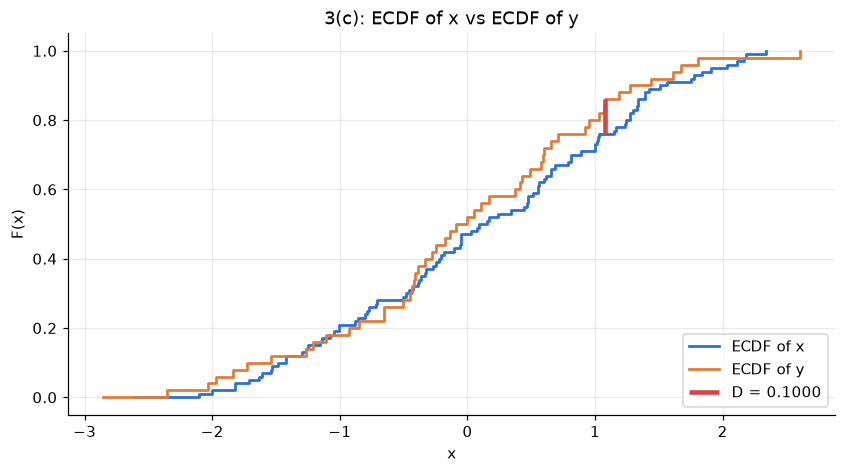

In [37]:
plot_ecdf_vs_cdf(x, other_sample=y, D=D_c, x_at_D=xD_c, labels=("x", "y"),
                 title="3(c): ECDF of x vs ECDF of y")

✍️ **Comment on (c).** Reject or not? How is this conclusion related to Problems 1 and 2?
Why can the Kolmogorov–Smirnov test detect differences that a test for means alone would miss?

*Your answer:*

1. **Test.** Two-sample Kolmogorov–Smirnov test of $H_0: F_X = F_Y$ vs. $H_1: F_X \ne F_Y$. We compare two samples with each other and no distribution $F_0$ is given, so we compare their two sample c.d.f.s.
2. **Rejection region.** $C = \{d \ge d_{1-\alpha}\}$, where for large samples $d_{0.95} \approx 1.358\sqrt{\frac{n+m}{nm}} = 1.358\sqrt{\frac{150}{5000}} \approx 0.235$.
3. **Decision.** The observed $d = 0.100 < 0.235$, so we **do not reject** $H_0$ at level 0.05.
4. **p-value.** p-value $= 0.885 > 0.05$, so we do not reject $H_0$. If $x$ and $y$ came from the same distribution, a distance of at least $0.100$ between their sample c.d.f.s would appear in about 88% of cases, so our result is very typical under $H_0$.

**Relation to Problems 1 and 2.** In Problem 1 we found no difference in means, and in Problem 2 no evidence that $\sigma_1^2 > \sigma_2^2$. A normal distribution is fully determined by its mean and variance, so if the means and variances are the same, the distributions are the same. The KS test agrees with this. It also agrees with the construction: both samples come from the same formula, so both should follow $\mathcal N(0,1)$.

**Why KS can see more than a test for means.** A test for means only compares the centers of the distributions. The KS test compares the whole c.d.f.s, so it reacts to any difference: in spread, in shape, in skewness. For example, $\mathcal N(0,1)$ and $\mathcal N(0,4)$ have the same mean, so a Z-test would not see a difference, but their c.d.f.s are clearly different and the KS test would detect it (for large enough samples).

---
## Problem 4 — Linear regression: marks vs study time

In this task you practice fitting a regression line to real-life data and analysing the results.
The file `data.csv` contains data on students: their study time and the corresponding marks.
Put it next to this notebook (or change `DATA_PATH`).

Your tasks:
* **(a)** Create a scatter plot of Marks vs Study Time and comment on it briefly.
* **(b)** Fit a linear regression model with marks as the dependent variable and study time as the independent variable.
* **(c)** Evaluate the goodness of fit of the fitted line.
* **(d)** Test whether study time is significant in predicting marks: find the test statistic and the p-value, and make a conclusion.
* **(e)** If Alice studies for approximately 8 hours, what mark can we predict for her?
* **(f)** Suggest up to three ideas to potentially improve prediction accuracy.

In [38]:
DATA_PATH = "data.csv"
X_COL, Y_COL = "time_study", "Marks"   # independent / dependent variable

df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())

t = df[X_COL].to_numpy(dtype=float)   # study time (hours)
m = df[Y_COL].to_numpy(dtype=float)   # marks
N = len(t)
print(f"N = {N},  study time range: [{t.min():.3f}, {t.max():.3f}]")

(100, 2)


,time_study,Marks
0,4.508,19.202
1,0.096,7.734
2,3.133,13.811
3,7.909,53.018
4,7.811,55.299


N = 100,  study time range: [0.096, 7.957]


### (a) Scatter plot *(implemented)*

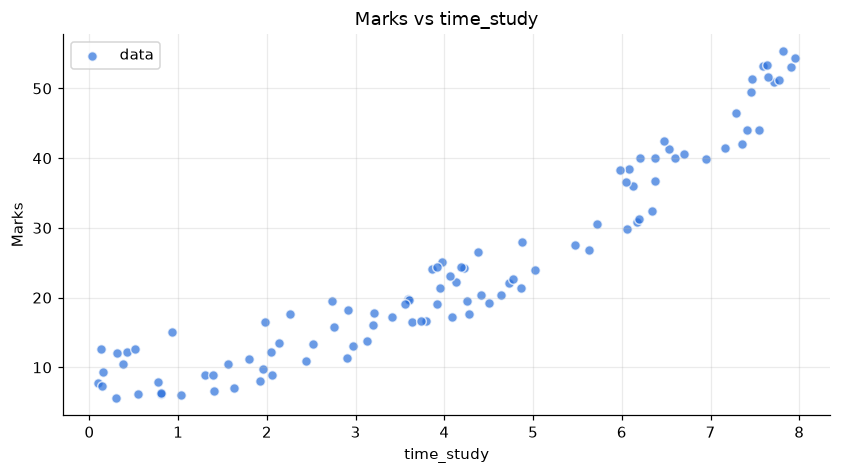

In [39]:
plot_regression(t, m, xlabel=X_COL, ylabel=Y_COL)

✍️ **Comments on (a).** Is the relationship roughly linear? Positive or negative? Any outliers, heteroscedasticity, saturation?

*Your answer:* The scatter plot shows a strong positive relationship between study time and marks. As study time increases, marks generally increase. However, the relationship does not appear perfectly linear: it seems somewhat curved, with marks increasing more rapidly at higher study times. There are no obvious extreme outliers, although some variability is present at similar study times. The relationship does not appear to show saturation.

### (b) Fit the linear model $\ \text{Marks} = \beta_0 + \beta_1\,\text{StudyTime} + \varepsilon$

**Notation.** For student $i = 1, \dots, N$, let $t_i$ be the study time and $m_i$ the mark. Let $\bar t = \frac1N \sum_{i=1}^N t_i$ and $\bar m = \frac1N \sum_{i=1}^N m_i$ be their sample means, and
$$S_{tt} = \sum_{i=1}^{N} (t_i-\bar t)^2, \qquad S_{tm} = \sum_{i=1}^{N} (t_i-\bar t)(m_i-\bar m).$$
$S_{tt}$ measures how spread out the study times are. $S_{tm}$ measures how study time and marks vary together: it is positive if students who study longer than average tend to get higher marks than average.

The coefficients are found by the **least squares method**. For a candidate line $\beta_0 + \beta_1 t$, the residual of student $i$ is $m_i - (\beta_0 + \beta_1 t_i)$, the vertical distance from the point to the line. Among all possible lines, we choose the one with the **smallest sum of squared residuals**, i.e. we choose $\beta_0, \beta_1$ that minimise
$$\sum_{i=1}^{N} \big(m_i - \beta_0 - \beta_1 t_i\big)^2.$$
Setting the partial derivatives of this sum (with respect to $\beta_0$ and $\beta_1$) to zero and solving the resulting two linear equations gives the **least squares estimates (LSE)** (you do not need to derive them):
$$\hat\beta_1 = \frac{S_{tm}}{S_{tt}}, \qquad \hat\beta_0 = \bar m - \hat\beta_1 \bar t.$$

In [47]:
# TODO: compute by hand with NumPy (no fitting library here)
t_bar, m_bar = np.mean(t), np.mean(m)
S_tt = np.sum((t - t_bar)**2)
S_tm = np.sum((t - t_bar) * (m - m_bar))
beta1_hat = S_tm / S_tt
beta0_hat = m_bar - beta1_hat * t_bar

report("Problem 4(b): least-squares fit", beta0=beta0_hat, beta1=beta1_hat)

# TODO (verification): fit = stats.linregress(t, m)
fit = None
if fit is not None:
    compare("beta1", beta1_hat, fit.slope)
    compare("beta0", beta0_hat, fit.intercept)

── Problem 4(b): least-squares fit ───────────────────
  beta0 : 1.2239
  beta1 : 5.6888


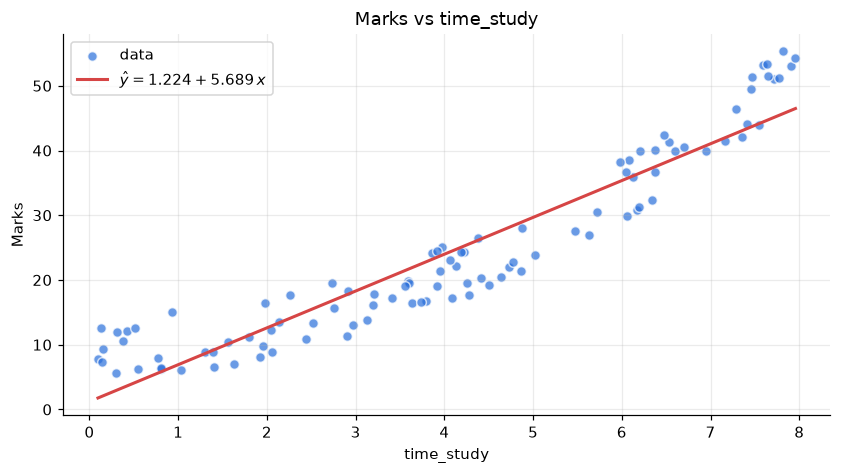

In [48]:
plot_regression(t, m, beta0=beta0_hat, beta1=beta1_hat, xlabel=X_COL, ylabel=Y_COL)

#### Conclusion
Using the least-squares method, we obtained:

\[
$\hat\beta_1=\frac{S_{tm}}{S_{tt}}=\frac{3171.1452}{557.4414}\approx5.68875$
\]

\[
$\hat\beta_0=\bar m-\hat\beta_1\bar t
\approx24.41769-5.68875(4.07714)
\approx1.22386.$
\]

Therefore, the fitted linear regression model is:

\[
$\boxed{\widehat{\text{Marks}}=1.22386+5.68875\cdot\text{StudyTime}}$
\]

The slope is positive, indicating that an additional hour of study time is associated with an average increase of approximately 5.69 marks. The intercept indicates a predicted mark of approximately 1.22 when study time is zero. The regression line captures the overall positive trend in the data, although it does not fully capture the curvature visible in the scatter plot.

### (c) Goodness of fit

**Notation.** Let $\hat m_i = \hat\beta_0 + \hat\beta_1 t_i$ be the **fitted values** (the marks predicted by the line) and $e_i = m_i - \hat m_i$ the **residuals**. The sums of squares are
$$SS_{tot} = \sum_{i=1}^{N} (m_i - \bar m)^2, \qquad SS_{res} = \sum_{i=1}^{N} e_i^2 = \sum_{i=1}^{N} (m_i - \hat m_i)^2.$$
$SS_{tot}$ is the total variability of the marks around their mean. $SS_{res}$ is the variability that remains around the fitted line, i.e. the part the line does not explain. The **coefficient of determination** is
$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}.$$

Compute the fitted values, residuals, $SS_{res}$, $SS_{tot}$ and $R^2$. Also check that for simple regression $R^2 = r^2$, where
$$r = \frac{S_{tm}}{\sqrt{S_{tt}\,S_{mm}}}, \qquad S_{mm} = \sum_{i=1}^{N} (m_i - \bar m)^2,$$
is the **sample correlation coefficient** between $t$ and $m$ (`np.corrcoef(t, m)[0, 1]`).

In [49]:
# TODO
fitted = beta0_hat + beta1_hat * t     # beta0_hat + beta1_hat * t
residuals = m - fitted     # m - fitted
SS_res = np.sum(residuals**2)
SS_tot = np.sum((m - m_bar)**2)
R2 = 1 - SS_res / SS_tot
r = np.corrcoef(t, m)[0, 1]       # sample correlation coefficient between t and m

report("Problem 4(c): goodness of fit", SS_res=SS_res, SS_tot=SS_tot, R2=R2, r_squared=None if r is None else r**2)

── Problem 4(c): goodness of fit ─────────────────────
  SS_res    : 2278.9031
  SS_tot    : 20318.7566
  R2        : 0.8878
  r_squared : 0.8878


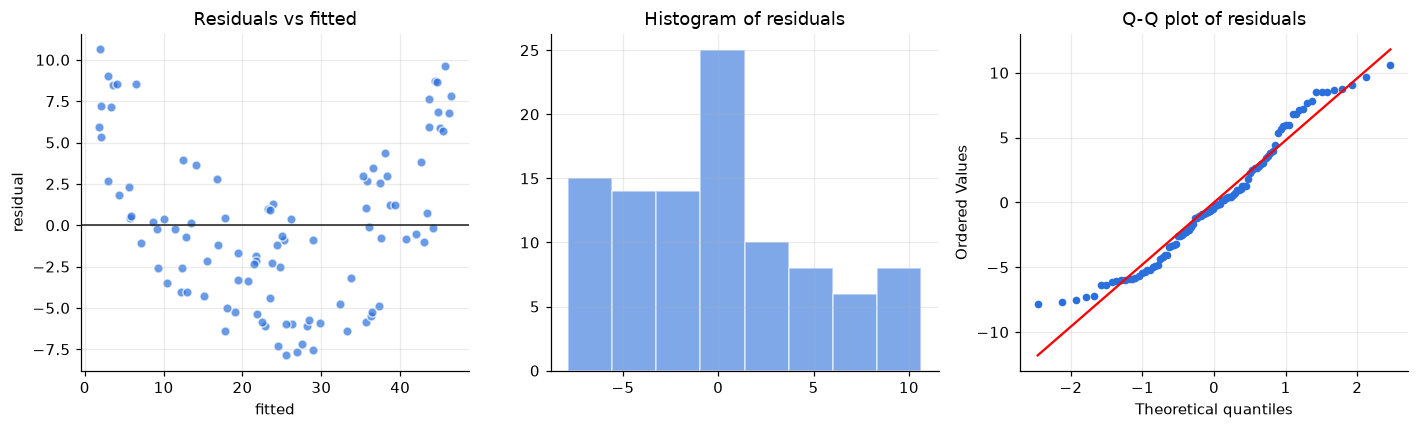

In [50]:
plot_residuals(fitted, residuals)

✍️ **Comments on (c).** Interpret $R^2$ in words. Do the residual plots support the model assumptions (linearity, constant variance, normal errors)?

*Your answer:* 
The coefficient of determination is \(R^2=0.8878\), meaning that approximately 88.78% of the variation in marks is explained by the linear regression model using study time. The correlation coefficient is \(r=0.9423\), indicating a strong positive linear association.

However, the residuals-versus-fitted plot shows a noticeable curved pattern rather than random scatter around zero. This suggests that the linearity assumption may not be fully satisfied. The residuals also exhibit some variation in spread, indicating possible heteroscedasticity. The histogram and Q-Q plot suggest that the residuals are not perfectly normally distributed, particularly in the tails.

Therefore, despite the high \(R^2\), the linear model may not fully capture the relationship between study time and marks. A nonlinear model could potentially provide a better fit.

### (d) Is study time significant for predicting marks?

We test whether the slope is zero, i.e. whether study time has no linear effect on marks.

**Fact.** Assume the errors $\varepsilon_i$ are i.i.d. $\mathcal N(0,\sigma^2)$. If $\beta_1 = 0$, then
$$T = \frac{\hat\beta_1}{\operatorname{SE}(\hat\beta_1)} \sim t_{N-2}, \qquad \operatorname{SE}(\hat\beta_1) = \sqrt{\frac{\hat\sigma^2}{S_{tt}}}, \qquad \hat\sigma^2 = \frac{SS_{res}}{N-2}.$$

✍️ **Hypotheses and rejection region.** State $H_0$ and $H_1$ in terms of $\beta_1$, and write the rejection region of the level-0.05 test.

*Your answer:* 

1. Hypotheses
Our regression model is:
\[
$M=\beta_0+\beta_1T+\varepsilon$
\]

We test the slope \($\beta_1$\).
Null hypothesis
\[
$\boxed{H_0:\beta_1=0}$
\]

This means there is no linear relationship between study time and marks in the population.
Alternative hypothesis
\[
$\boxed{H_1:\beta_1\neq0}$
\]

This means there is a nonzero linear relationship.

This is a two-sided test, because we are checking whether the slope is different from zero in either direction.

2. Why do we use the t-test?
Under the assumptions that errors are independent, normally distributed, and have equal variance:
\[
$\varepsilon_i\sim N(0,\sigma^2)$
\]

The test statistic is:
\[
$\boxed{T=\frac{\hat\beta_1}{SE(\hat\beta_1)}}$
\]

Under the null hypothesis:
\[
$\boxed{T\sim t_{N-2}}$
\]

Why \($N-2$\)?

We estimate two parameters from the data:
- \($\beta_0\) — intercept
- \($\beta_1\) — slope
Therefore, the degrees of freedom are:
\[
$df=N-2=100-2$
\]

\[
$\boxed{df=98}$
\]


3. Calculate residual variance
First, we estimate the variance of the errors:
\[
$\hat\sigma^2=\frac{SS_{res}}{N-2}$
\]

We already calculated:
\[
$SS_{res}=2278.9031$
\]

Thus:
\[
$\hat\sigma^2=\frac{2278.9031}{98}$
\]

\[
$\boxed{\hat\sigma^2\approx23.25411}$
\]

This is the estimated variance of the errors.

The estimated standard deviation of the errors is:
\[
$\hat\sigma=\sqrt{23.25411}$
\]

\[
$\boxed{\hat\sigma\approx4.82225}$
\]


4. Calculate the standard error of the slope
The formula from your notebook is:
\[
$SE(\hat\beta_1)=\sqrt{\frac{\hat\sigma^2}{S_{tt}}}$
\]

Substitute:
\[
$SE(\hat\beta_1)=
\sqrt{\frac{23.25411}{557.44143}}$
\]

\[
$\boxed{SE(\hat\beta_1)\approx0.204244}$
\]

The standard error measures how uncertain our estimate of the slope is.

Our slope estimate is approximately 5.689, and its standard error is only about 0.204. This is a very large slope relative to its uncertainty.

5. Calculate the t-statistic
\[
$T=\frac{\hat\beta_1}{SE(\hat\beta_1)}$
\]

\[
$T=\frac{5.68875}{0.204244}$
\]

\[
$\boxed{T\approx27.85266}$
\]

This is extremely far from zero.

6. Critical value and rejection region
Our significance level:
\[
$\alpha=0.05$
\]

Because the test is two-sided, we split alpha between the two tails:
\[
$\frac{\alpha}{2}=0.025$
\]

The critical value is:
\[
$t_{0.975,98}\approx1.98447$
\]

The rejection region is:
\[
$\boxed{C=\{|T|\geq1.98447\}}$
\]

Our observed statistic:
\[
$|27.85266|>1.98447$
\]

Therefore, we are in the rejection region.
\[
$\boxed{\text{Reject }H_0}$
\]


7. Calculate the p-value
The p-value is:
\[
$p=2P(T_{98}\geq|T_{\text{obs}}|)$
\]

\[
$p=2P(T_{98}\geq27.85266)$
\]

Our calculated value:
\[
$\boxed{p\approx2.36\times10^{-48}}$
\]

This is essentially zero for practical purposes and is vastly smaller than 0.05.

8. Conclusion
We reject the null hypothesis.

There is extremely strong statistical evidence that the slope is different from zero. In this dataset, the slope is positive, so study time is a statistically significant positive linear predictor of marks.

This does not prove that studying causes higher marks, because regression by itself does not establish causation. It establishes a statistically significant association.

In [51]:
# TODO
sigma2_hat = SS_res / (N - 2)    # residual variance estimate
se_beta1 = np.sqrt(sigma2_hat / S_tt)
T_stat = beta1_hat / se_beta1
df_reg = N - 2    # degrees of freedom
t_crit = stats.t.ppf(0.975, df_reg)    # two-sided critical value at level 0.05
p_value_4 = 2 * stats.t.sf(abs(T_stat), df_reg)    # two-sided p-value
reject_4 = p_value_4 < ALPHA

report("Problem 4(d): t-test for the slope", sigma2_hat=sigma2_hat, SE_beta1=se_beta1,
       T=T_stat, df=df_reg, critical_value=t_crit, p_value=p_value_4, reject_H0=reject_4)
if fit is not None:
    compare("SE(beta1)", se_beta1, fit.stderr)
    compare("p-value", p_value_4, fit.pvalue)

── Problem 4(d): t-test for the slope ────────────────
  sigma2_hat     : 23.2541
  SE_beta1       : 0.2042
  T              : 27.8527
  df             : 98
  critical_value : 1.9845
  p_value        : 2.356e-48
  reject_H0      : True


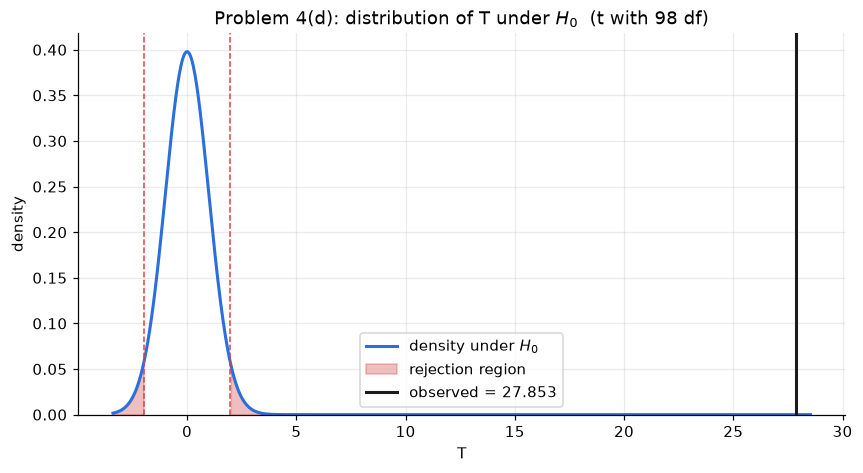

In [52]:
if _ready(df_reg):
    plot_test_distribution(
        stats.t(df_reg), observed=T_stat,
        reject_left=None if t_crit is None else -t_crit, reject_right=t_crit,
        title=f"Problem 4(d): distribution of T under $H_0$  (t with {df_reg} df)", xlabel="T",
    )
else:
    print("Fill in df_reg to see the plot.")

✍️ **Conclusion for (d).** Is study time a significant predictor? Interpret the p-value.

*Your answer:* We test \($H_0:\beta_1=0$\) against \($H_1:\beta_1\neq0$\) at significance level \($\alpha=0.05$\).

The observed test statistic is \($T=27.8527$\), which exceeds the critical value in absolute terms, \($t_{crit}=1.9845$\). The p-value is approximately \($2.356\times10^{-48}$\), which is much smaller than \(0.05\).

Therefore, we reject the null hypothesis. There is extremely strong statistical evidence that study time is a significant predictor of marks. Since the estimated slope is positive (\($\hat\beta_1=5.6888$\)), study time is positively associated with marks. Students who study longer tend to achieve higher marks.

However, statistical significance does not establish causation, and the residual analysis suggests that the simple linear model may not fully describe the relationship.

### (e) Prediction for Alice (≈ 8 hours of study)
*Optional (bonus understanding):* also compute a 95% **prediction interval**
$\hat m_0 \pm t_{0.975,\,N-2}\,\hat\sigma\sqrt{1 + \frac1N + \frac{(t_0-\bar t)^2}{S_{tt}}}$, where $\hat m_0 = \hat\beta_0 + \hat\beta_1 t_0$,
and explain how it differs from a confidence interval for the mean response.

In [46]:
t_alice = 8

m_alice = beta0_hat + beta1_hat * t_alice

t_q = stats.t.ppf(1 - ALPHA / 2, N - 2)
margin = t_q * np.sqrt(sigma2_hat) * np.sqrt(1 + 1 / N + (t_alice - t_bar) ** 2 / S_tt)
pi_low, pi_high = m_alice - margin, m_alice + margin

report("Problem 4(e): prediction", predicted_mark=m_alice, PI_low=pi_low, PI_high=pi_high)
plot_regression(t, m, beta0=beta0_hat, beta1=beta1_hat, x_new=t_alice, y_new=m_alice,
                xlabel=X_COL, ylabel=Y_COL)

TypeError: unsupported operand type(s) for *: 'NoneType' and 'int'

✍️ **Comment on (e).** Is $t_0 = 8$ inside the range of observed study times? Why does that matter?

*Your answer:*

The predicted mark for Alice is $\hat m_0 = \hat\beta_0 + 8\hat\beta_1$ (see the output above), and the 95% prediction interval is $[\text{PI\_low},\ \text{PI\_high}]$.

The largest observed study time is about 7.96 hours, so $t_0 = 8$ is just outside the range of the data. This matters because we only know that the line fits well where we have data. Outside this range we are extrapolating: we assume the relationship stays the same, but we cannot check it. Here $t_0$ is very close to the maximum, so the prediction is still reasonable, but it is less reliable than for a typical study time. This is also why the interval is wider: the term $\frac{(t_0-\bar t)^2}{S_{tt}}$ grows when $t_0$ is far from $\bar t$.

**Prediction interval vs confidence interval.** A confidence interval for the mean response estimates the *average* mark of all students who study 8 hours. A prediction interval is for the mark of *one* student (Alice). It also includes her individual random error $\varepsilon$, which gives the extra "1 +" under the square root, so the prediction interval is always wider.

### (f) Ideas to improve prediction accuracy

1. **Add other features.** Marks depend not only on study time. For example, the number of courses a student takes (if it is in the data), attendance or previous grades could explain part of the remaining variability. This would be multiple linear regression.
2. **Add a non-linear term.** If the scatter plot or the residual plot shows a curve, a straight line is not enough. We can add $t^2$ to the model: $\text{Marks} = \beta_0 + \beta_1 t + \beta_2 t^2 + \varepsilon$.
3. **More data and checking outliers.** More students, especially with long study times, would make the estimates more precise and reduce extrapolation. Outliers should be checked, because a few strange points can move the line a lot.

---
## Summary of results
*(Implemented — fills in automatically.)*

In [ ]:
summary = pd.DataFrame([
    ["1: μ1 = μ2 (σ² known)",          "two-sample Z", z_stat,  p_value_1, reject_1],
    ["2: σ1² = σ2² vs σ1² > σ2²",      "F-test",       F_stat,  p_value_2, reject_2],
    ["3a: x ~ N(0, 1)",                "Kolmogorov",   D_a,     p_value_a, reject_a],
    ["3b: |x| ~ Exp(1)",               "Kolmogorov",   D_b,     p_value_b, reject_b],
    ["3c: x and y same distribution",  "Kolmogorov–Smirnov", D_c,     p_value_c, reject_c],
    ["4d: β1 = 0",                     "t-test",       T_stat,  p_value_4, reject_4],
], columns=["Hypothesis H0", "Test", "Statistic", "p-value", "Reject at 0.05"])
summary

✍️ **Consistency check.**

* Problems 1, 2 and 3(c) agree with each other: we found no difference in means, no difference in variances, and no difference in the whole distributions of $x$ and $y$. This matches the construction, since both samples are generated from the same sequence $a_k$ and should follow $\mathcal N(0,1)$.
* 3(a) does not reject $\mathcal N(0,1)$, as expected, although the p-value is close to 0.05.
* 3(b) does not reject $\text{Exp}(1)$ even though $|x|$ is actually half-normal. This is a type II error: the two c.d.f.s differ by at most about 0.094, which is too small to detect with 100 observations.
* 4(d) rejects $\beta_1 = 0$, so study time is a significant predictor of marks. This agrees with the clear positive trend on the scatter plot and with the value of $R^2$.